In [1]:

import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from math import sqrt, log2
import seaborn as sns
import numpy as np
import cartopy
from scipy.stats import kurtosis, entropy, gaussian_kde
from scipy.special import rel_entr, kl_div
from scipy.stats import norm


from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out

def shannon_entropy(p_i):
    entropy = entropy(p_i, base=2)
    ent = -sum()


In [ ]:

import warnings

import numpy as np
import numpy.linalg as la
from numpy import log
from scipy.special import digamma
from sklearn.neighbors import BallTree, KDTree

def add_noise(x, intens=1e-10):
    # small noise to break degeneracy, see doc.
    return x + intens * np.random.random_sample(x.shape)

def build_tree(points):
    if points.shape[1] >= 20:
        return BallTree(points, metric="chebyshev")
    return KDTree(points, metric="chebyshev")

estimate_grop
def query_neighbors(tree, x, k):
    return tree.query(x, k=k + 1)[0][:, k]


def avgdigamma(points, dvec):
    # This part finds number of neighbors in some radius in the marginal space
    # returns expectation value of <psi(nx)>
    tree = build_tree(points)
    dvec = dvec - 1e-15
    num_points = count_neighbors(tree, points, dvec)
    return np.mean(digamma(num_points))

def count_neighbors(tree, x, r):
    return tree.query_radius(x, r, count_only=True)


def mi(x, y, z=None, k=3, base=2, alpha=0):
    """Mutual information of x and y (conditioned on z if z is not None)
    x, y should be a list of vectors, e.g. x = [[1.3], [3.7], [5.1], [2.4]]
    if x is a one-dimensional scalar and we have four samples
    """
    assert len(x) == len(y), "Arrays should have same length"
    assert k <= len(x) - 1, "Set k smaller than num. samples - 1"
    x, y = np.asarray(x), np.asarray(y)
    x, y = x.reshape(x.shape[0], -1), y.reshape(y.shape[0], -1)
    x = add_noise(x)
    y = add_noise(y)
    points = [x, y]
    if z is not None:
        z = np.asarray(z)
        z = z.reshape(z.shape[0], -1)
        points.append(z)
    points = np.hstack(points)
    # Find nearest neighbors in joint space, p=inf means max-norm
    tree = build_tree(points)
    dvec = query_neighbors(tree, points, k)
    if z is None:
        a, b, c, d = (
            avgdigamma(x, dvec),
            avgdigamma(y, dvec),
            digamma(k),
            digamma(len(x)),
        )
        if alpha > 0:
            d += lnc_correction(tree, points, k, alpha)
    else:
        xz = np.c_[x, z]
        yz = np.c_[y, z]
        a, b, c, d = (
            avgdigamma(xz, dvec),
            avgdigamma(yz, dvec),
            avgdigamma(z, dvec),
            digamma(k),
        )
    return (-a - b + c + d) / log(base)

In [3]:

datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"
dat = pd.read_csv(datapath+"seasonal-dayofweek-no2-estimates.csv")

def F_pixel_stats(dat):
   y_true = dat.sfc_no2_mean
   y_pred = dat.no2_estimate
   bias = (y_pred-y_true).mean()
   rmse = sqrt(mean_squared_error(y_true, y_pred))
   r2 = r2_score(y_true, y_pred)
   # covar = np.cov(y_true, y_pred, ddof=0)
   corr_coef = np.corrcoef(y_true, y_pred, rowvar=False)[0,1]
   covar = np.nan
   out = pd.Series({'r2': r2, 'bias': bias, 'rmse':rmse,
                    'covar': covar, 'corr_coef': corr_coef})
   return out

# def F_ent_metrics(dat):
#    y_true = dat.sfc_no2_mean
#    y_pred = dat.no2_estimate
#    rel_ent = entropy(y_true, y_pred, base=2, nan_policy='omit')
#    mut_inf = mutual_info_regression(y_true.to_frame(), y_pred.to_frame())
#    out = pd.Series({'rel_ent' : rel_ent, 'mut_inf': mut_inf})
#    return out

def F_rel_ent(x,y):

    linspace_bins = 500

    pk_kde = gaussian_kde(x, bw_method='scott')  # or 'silverman', or a float
    pk_grid = np.linspace(x.min(), x.max(), linspace_bins)
    pk_dens = pk_kde(pk_grid)
    pk_pdf =  pk_dens / sum(pk_dens)

    qk_kde = gaussian_kde(y, bw_method='scott')  # or 'silverman', or a float
    qk_grid = np.linspace(y.min(), y.max(), linspace_bins)
    qk_dens = qk_kde(qk_grid)
    qk_pdf =  qk_dens / sum(qk_dens)

    rel_ent = sum(pk_pdf * np.log2(pk_pdf/qk_pdf))

    X_mi = np.asarray(x).reshape(-1, 1)
    y_mi = np.asarray(y).ravel()

    mut_info = mi(X_mi, y_mi, k=10, base=2)

    out = pd.Series({'rel_ent': rel_ent, 
                     'mut_info': mut_info})
    return out 




TypeError: F_rel_ent() missing 1 required positional argument: 'y'

In [ ]:

rel_ent_wide = (
    dat.groupby(['latitude','longitude','season'])
    .apply(lambda x: F_rel_ent(x.sfc_no2_mean, x.no2_estimate))
    .reset_index())

rel_ent_long = (
    dat.groupby(['latitude','longitude','season'])
    .apply(lambda x: F_rel_ent(x.sfc_no2_mean, x.no2_estimate))
    .melt(ignore_index=False)
    .reset_index())

rel_ent_all_wide = (
    dat.groupby(['season'])
    .apply(lambda x: F_rel_ent(x.sfc_no2_mean, x.no2_estimate))
    .reset_index())

pixel_stats_wide = (
    dat.groupby(['latitude','longitude','season','split'])
    .apply(F_pixel_stats)
    .reset_index())

pixel_stats_long = (
    dat.groupby(['latitude','longitude','season','split'])
    .apply(F_pixel_stats)
    .melt(ignore_index=False)
    .reset_index())

TypeError: F_rel_ent() missing 1 required positional argument: 'y'

In [17]:
print(rel_ent_wide.head())

print(rel_ent_long.head())

   latitude  longitude  season   rel_ent
0     41.65     -87.61    Fall  1.048655
1     41.65     -87.61  Spring  0.795119
2     41.65     -87.61  Winter  0.448548
3     41.65     -87.57    Fall  0.379002
4     41.65     -87.57  Spring  0.124180
   latitude  longitude  season variable     value
0     41.65     -87.61    Fall  rel_ent  1.048655
1     41.65     -87.61  Spring  rel_ent  0.795119
2     41.65     -87.61  Winter  rel_ent  0.448548
3     41.65     -87.57    Fall  rel_ent  0.379002
4     41.65     -87.57  Spring  rel_ent  0.124180


In [ ]:

y_true = dat['sfc_no2_mean']
y_pred = dat['no2_estimate']


pk_kde = gaussian_kde(y_true, bw_method='scott')  # or 'silverman', or a float
pk_grid = np.linspace(y_true.min(), y_true.max(), 1000)
pk_dens = pk_kde(pk_grid)
pk_pdf =  pk_dens / sum(pk_dens)
H_pk = -sum(pk_pdf * np.log2(pk_pdf))

qk_kde = gaussian_kde(y_pred, bw_method='scott')  # or 'silverman', or a float
qk_grid = np.linspace(y_pred.min(), y_pred.max(), 1000)
qk_dens = qk_kde(qk_grid)
qk_pdf =  qk_dens / sum(qk_dens)
H_qk = -sum(qk_pdf * np.log2(qk_pdf))

rel_ent = sum(rel_entr(pk_pdf, qk_pdf))
rel_ent3 = sum(pk_pdf * np.log2(pk_pdf/qk_pdf))


print(H_pk)
print(H_qk)
print(rel_ent)
print(rel_ent3)

8.288284647263351
8.347751745893504
5.353060596382561
7.722833975979248


In [48]:
x = y_true
y = y_pred

# pk_kde = gaussian_kde(x, bw_method='scott')  # or 'silverman', or a float
# pk_grid = np.linspace(x.min(), x.max(), 100)
# pk_dens = pk_kde(pk_grid)
# pk_pdf =  pk_dens / np.nansum(pk_dens)
# H_pk = -sum(pk_pdf * np.log2(pk_pdf))

# qk_kde = gaussian_kde(y, bw_method='scott')  # or 'silverman', or a float
# qk_grid = np.linspace(y.min(), y.max(), 100)
# qk_dens = qk_kde(qk_grid)
# qk_pdf =  qk_dens / np.nansum(qk_dens)
# H_qk = -sum(qk_pdf * np.log2(qk_pdf))

counts, x_edges, y_edges = np.histogram2d(x, y, bins=100, density=False)

joint_prob = counts / counts.sum()

# J_xy = -np.nansum(np.nansum(joint_prob * np.log2(joint_prob)))

# I_xy = H_pk + H_qk - J_xy

# --- Marginals derived from the SAME joint distribution ---
px = joint_prob.sum(axis=1)  # marginal over X, shape: (100,)
py = joint_prob.sum(axis=0)  # marginal over Y, shape: (100,)

# --- Entropy helper (handles 0*log(0) correctly) ---
def entropy(p):
    p = p[p > 0]  # drop zeros before log
    return -np.sum(p * np.log2(p))

H_x   = entropy(px)
H_y   = entropy(py)
H_xy  = entropy(joint_prob.flatten())

I_xy  = H_x + H_y - H_xy



# print(joint_prob)
print(I_xy)


0.40817919785139267


0.2700267572150823
0.3906082297280529


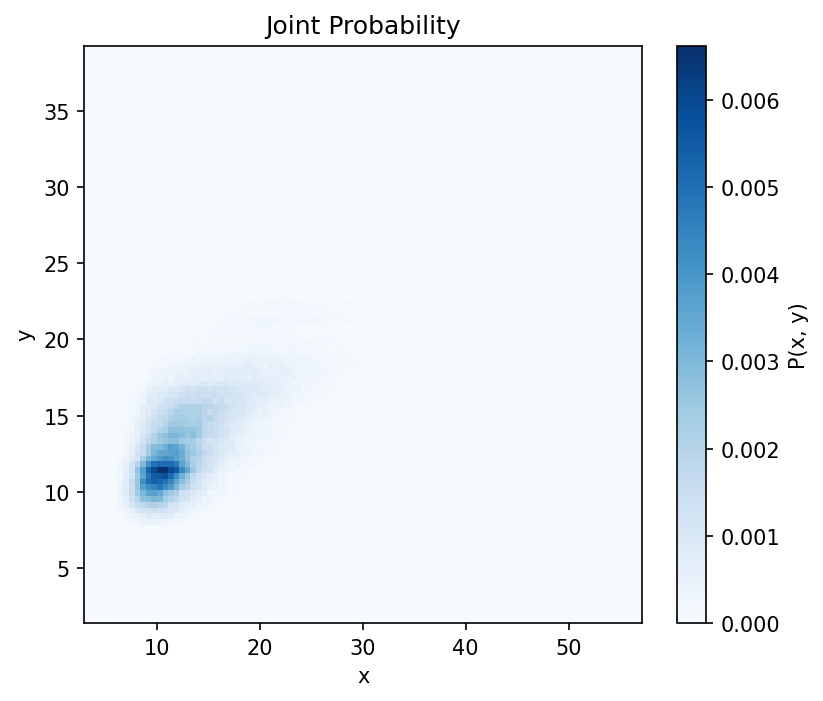

In [56]:
X_mi = np.asarray(x).reshape(-1, 1)
y_mi = np.asarray(y).ravel()

I_xy = mutual_info_regression(
    X_mi, y_mi,
    n_neighbors=3,      # k — typically 3-10; larger = smoother
    random_state=0
)[0]

print(I_xy)


I_xy = mi(X_mi, y_mi, k=10)

print(I_xy)
# Downsample very large joint grids to keep plotting responsive.
nx, ny = joint_prob.shape
plot_max_cells = 400
step = max(1, nx // plot_max_cells, ny // plot_max_cells)

if step > 1:
    x_idx = np.arange(0, nx + 1, step)
    y_idx = np.arange(0, ny + 1, step)
    if x_idx[-1] != nx:
        x_idx = np.r_[x_idx, nx]
    if y_idx[-1] != ny:
        y_idx = np.r_[y_idx, ny]

    joint_prob_plot = joint_prob[np.ix_(x_idx[:-1], y_idx[:-1])]
    x_edges_plot = x_edges[x_idx]
    y_edges_plot = y_edges[y_idx]
else:
    joint_prob_plot = joint_prob
    x_edges_plot = x_edges
    y_edges_plot = y_edges

plt.figure(figsize=(6, 5))
plt.pcolormesh(x_edges_plot, y_edges_plot, joint_prob_plot.T, cmap='Blues')
plt.colorbar(label='P(x, y)')
plt.xlabel('x'); plt.ylabel('y')
plt.title('Joint Probability')
plt.show()

In [ ]:
x = pd.DataFrame(y_true)
y = pd.DataFrame(y_pred)

p = norm.pdf(y_true)
q = norm.pdf(y_pred)

# scores = mutual_info_regression(x, y)

# rel_ent = np.sum(rel_entr(x,y))
# rel_ent

array([3.34903401e-47, 2.81819047e-38, 7.27317530e-40, ...,
       4.90614536e-32, 1.03071042e-25, 1.05769087e-43], shape=(143039,))

In [ ]:
entropy_spatial = (


    dat.groupby(['latitude','longitude','season'])
    .apply(F_rel_ent())

)

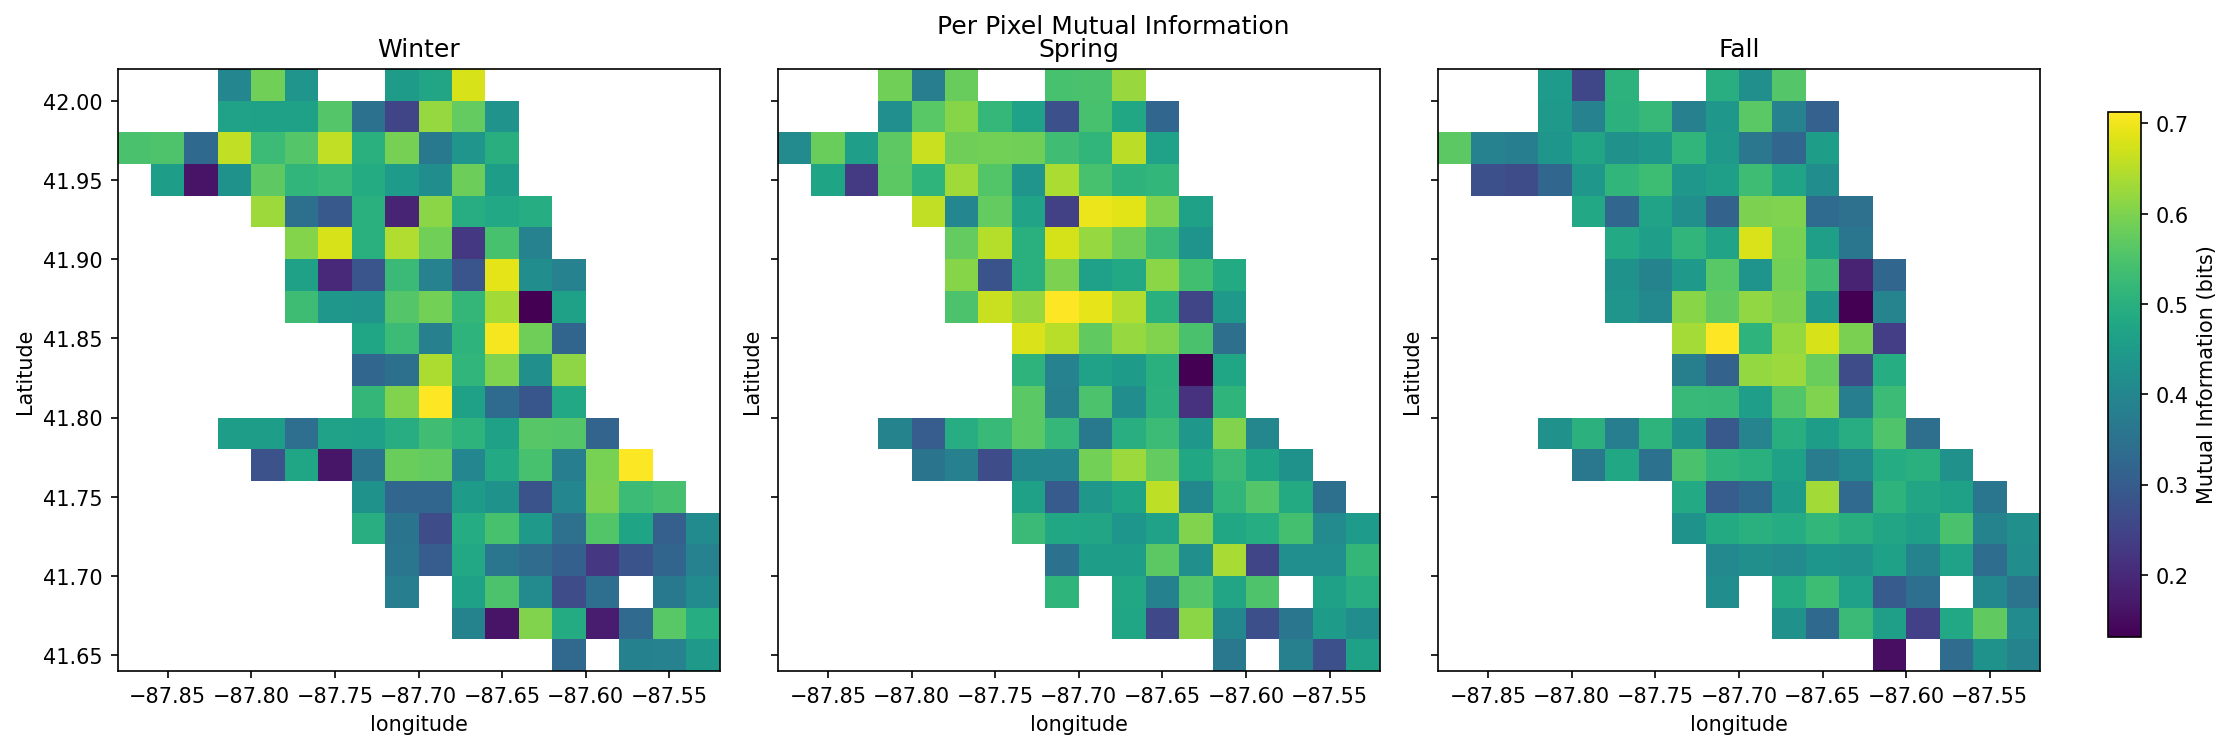

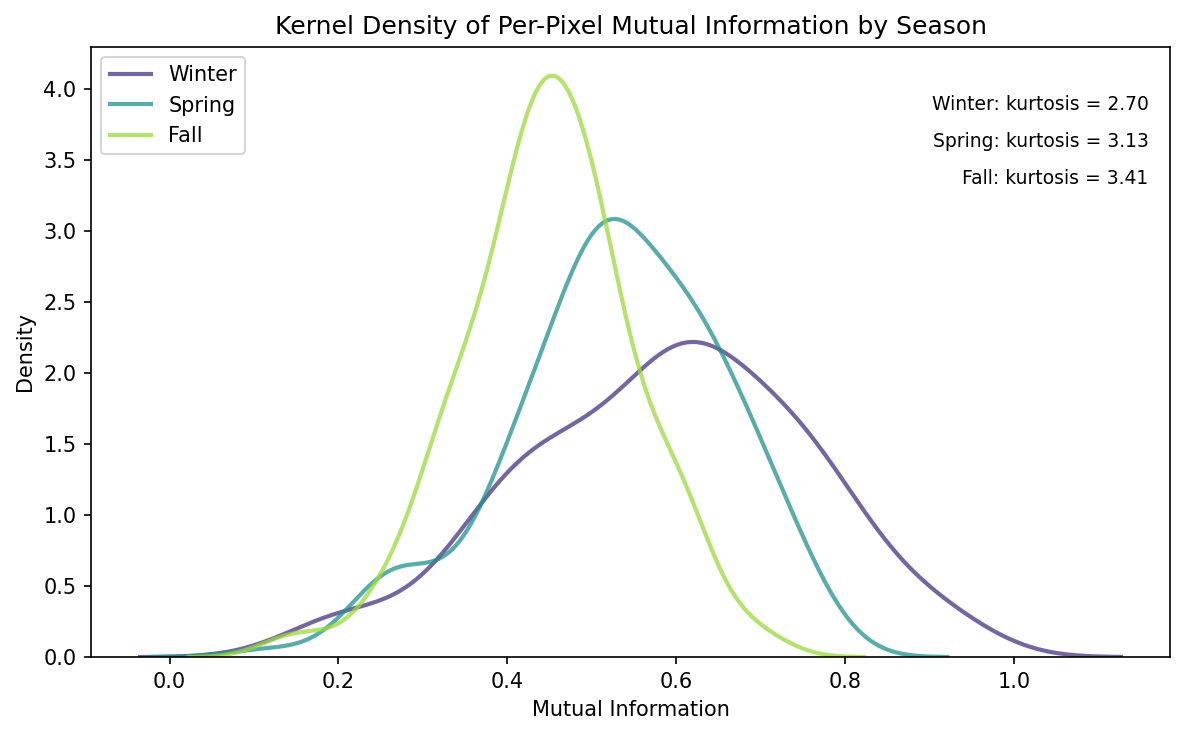

In [67]:

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
# season_order = ['Spring', 'Fall']
seasonal_maps = []
splits = ['']


for split in splits:
    seasonal_maps = []
    for season in season_order:
        season_subset = rel_ent_long.loc[
            (rel_ent_long['season'] == season) & (rel_ent_long['variable'] == 'mut_info'),
            ['latitude', 'longitude', 'value']
        ]
        if season_subset.empty:
            continue

        season_rast = season_subset.set_index(['latitude', 'longitude']).to_xarray()
        seasonal_maps.append((season, season_rast['value']))

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
    axes = axes.flatten()
    mappable = None

    for ax, (season, mean_map) in zip(axes, seasonal_maps):
        mappable = mean_map.plot(
            x='longitude',
            y='latitude',
            cmap='viridis',
            ax=ax,
            add_colorbar=False,
            # vmin=-1,
            # vmax=1
        )
        ax.set_box_aspect(1)
        ax.set_title(season)
        # ax.set_xlabel('Longitude')
        ax.set_ylabel('Latitude')

    for ax in axes[len(seasonal_maps):]:
        ax.set_visible(False)

    # Reserve space at right for a single shared colorbar
    plt.tight_layout(rect=[0, 0, 0.92, 0.97])

    if mappable is not None:
        cax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
        fig.colorbar(mappable, cax=cax, label='Mutual Information (bits)')

    fig.suptitle('Per Pixel Mutual Information ')
    plt.savefig('seasonal-mut-info-spatial-maps-'+split+'-data.png')
    plt.show()


seasonal_residuals = []

for season in season_order:
    if season not in rel_ent_wide['season'].dropna().unique():
        continue

    season_values = rel_ent_wide.loc[rel_ent_wide['season'] == season, 'mut_info'].dropna()
    if not season_values.empty:
        seasonal_residuals.append((season, season_values))

fig, ax = plt.subplots(figsize=(8, 5))
viridis_colors = plt.cm.viridis(np.linspace(0.15, 0.85, len(seasonal_residuals)))

for i, (season, values) in enumerate(seasonal_residuals):
    sns.kdeplot(
        values,
        ax=ax,
        label=season,
        fill=False,
        alpha=0.75,
        linewidth=2,
        color=viridis_colors[i]
    )

    kurt = kurtosis(values, fisher=False, bias=False)
    ax.text(
        0.98,
        0.92 - 0.06 * i,
        f'{season}: kurtosis = {kurt:.2f}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=9,
    )

ax.set_title('Kernel Density of Per-Pixel Mutual Information by Season')
ax.set_xlabel('Mutual Information')
ax.set_ylabel('Density')
ax.legend()
plt.tight_layout()
plt.savefig('mut-info-per-pixel-seasonal.png')
plt.show()

   latitude  longitude   rel_ent  mut_info
0     41.65     -87.61  0.506749  0.299260
1     41.65     -87.57  0.008191  0.361358
2     41.65     -87.55  0.035277  0.372411
3     41.65     -87.53  0.069167  0.419201
4     41.67     -87.67  0.196685  0.410104


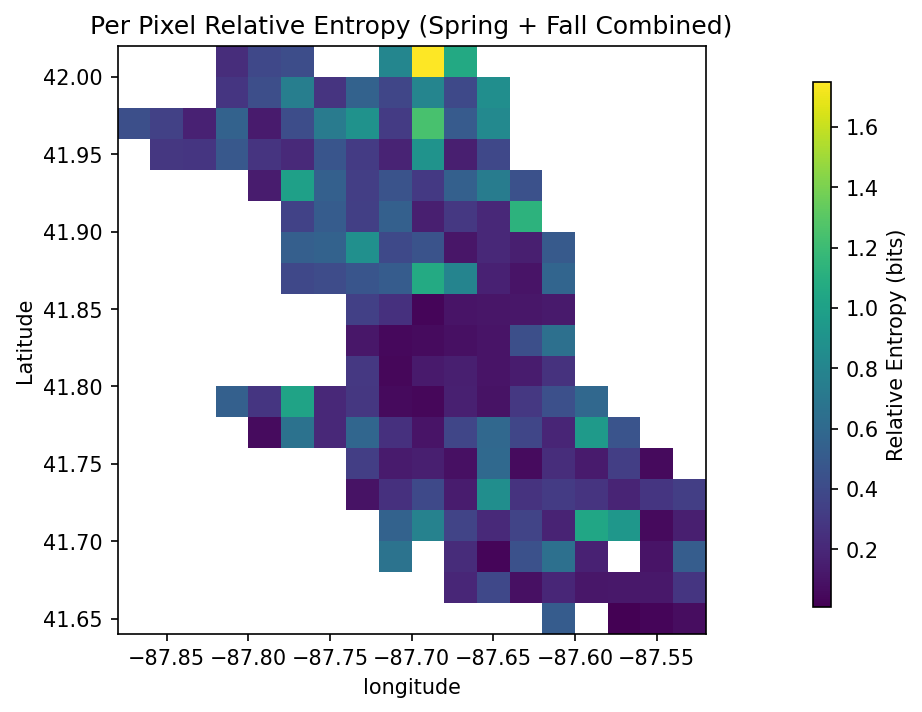

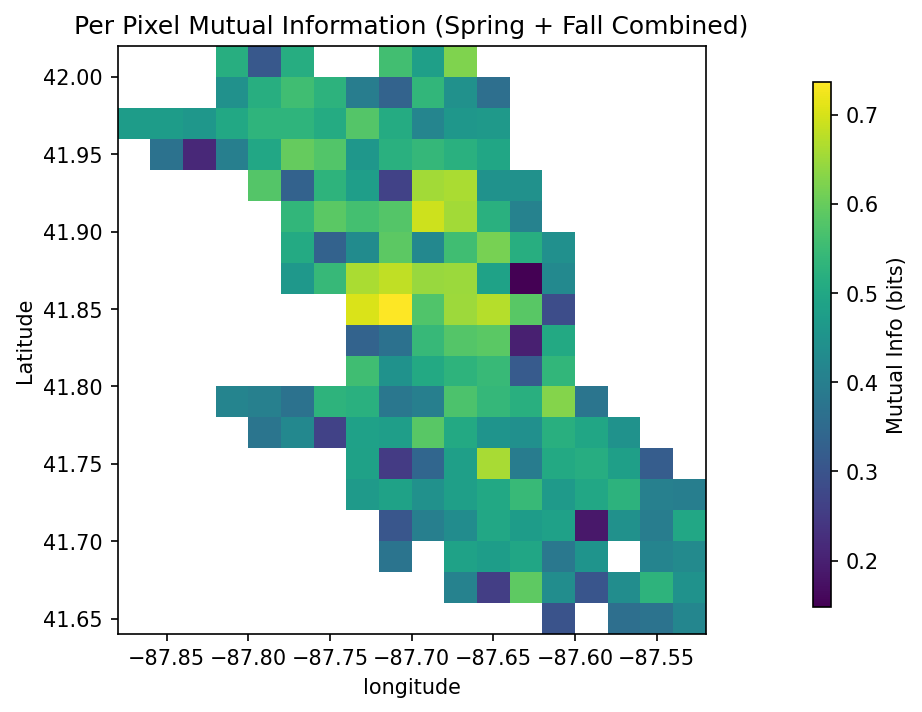

In [65]:
# Compute per-pixel relative entropy for Spring and Fall combined
season_subset = ['Spring', 'Fall']
dat_spring_fall = dat.loc[dat['season'].isin(season_subset)].copy()

rel_ent_pixel_wide = (
    dat_spring_fall.groupby(['latitude', 'longitude'])
    .apply(F_rel_ent)
    .reset_index()
)

print(rel_ent_pixel_wide.head())

# Build raster and plot a single spatial map
pixel_rast = rel_ent_pixel_wide.set_index(['latitude', 'longitude']).to_xarray()

fig, ax = plt.subplots(figsize=(6, 5))
mappable = pixel_rast['rel_ent'].plot(
    x='longitude',
    y='latitude',
    cmap='viridis',
    ax=ax,
    add_colorbar=False,
)

ax.set_box_aspect(1)
ax.set_title('Per Pixel Relative Entropy (Spring + Fall Combined)')
ax.set_ylabel('Latitude')

cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(mappable, cax=cax, label='Relative Entropy (bits)')

plt.tight_layout(rect=[0, 0, 0.9, 0.97])
plt.savefig('rel-ent-spatial-map-spring-fall.png')
plt.show()


fig, ax = plt.subplots(figsize=(6, 5))
mappable = pixel_rast['mut_info'].plot(
    x='longitude',
    y='latitude',
    cmap='viridis',
    ax=ax,
    add_colorbar=False,
)

ax.set_box_aspect(1)
ax.set_title('Per Pixel Mutual Information (Spring + Fall Combined)')
ax.set_ylabel('Latitude')

cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(mappable, cax=cax, label='Mutual Info (bits)')

plt.tight_layout(rect=[0, 0, 0.9, 0.97])
plt.savefig('mutual-info-spatial-map-spring-fall.png')
plt.show()


In [ ]:
rel_ent_all_wide = (
    dat.groupby(['latitude','longitude','season'])
    .apply(lambda x: F_rel_ent(x.sfc_no2_mean, x.no2_estimate))
    .reset_index())

rel_ent_pixel_wide = (
    dat_spring_fall.groupby(['latitude', 'longitude'])
    .apply(lambda x: F_rel_ent(x.sfc_no2_mean, x.no2_estimate))
    .reset_index()
)

print(rel_ent_pixel_wide.head())

# Build raster and plot a single spatial map
pixel_rast = rel_ent_pixel_wide.set_index(['latitude', 'longitude']).to_xarray()

fig, ax = plt.subplots(figsize=(6, 5))
mappable = pixel_rast['rel_ent'].plot(
    x='longitude',
    y='latitude',
    cmap='viridis',
    ax=ax,
    add_colorbar=False,
)

ax.set_box_aspect(1)
ax.set_title('Per Pixel Relative Entropy (Spring + Fall Combined)')
ax.set_ylabel('Latitude')

cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(mappable, cax=cax, label='Relative Entropy (bits)')

plt.tight_layout(rect=[0, 0, 0.9, 0.97])
plt.savefig('rel-ent-spatial-map-spring-fall.png')
plt.show()


fig, ax = plt.subplots(figsize=(6, 5))
mappable = pixel_rast['mut_info'].plot(
    x='longitude',
    y='latitude',
    cmap='viridis',
    ax=ax,
    add_colorbar=False,
)

ax.set_box_aspect(1)
ax.set_title('Per Pixel Mutual Information (Spring + Fall Combined)')
ax.set_ylabel('Latitude')

cax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
fig.colorbar(mappable, cax=cax, label='Mutual Info (bits)')

plt.tight_layout(rect=[0, 0, 0.9, 0.97])
plt.savefig('mutual-info-spatial-map-spring-fall.png')
plt.show()